In [1]:
import torch

x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y = torch.tensor([2.0, 4.0, 6.0, 8.0])     # asli jawab: y = 2x

w = torch.tensor(0.0, requires_grad=True)   # shuru mein w = 0 (galat)
lr = 0.01

for step in range(5):
    pred = x * w                            # model ka andaza
    loss = ((pred - y) ** 2).mean()         # galti (MSE)
    loss.backward()                         # gradient nikaalo
    with torch.no_grad():
        w -= lr * w.grad                    # w = w - lr * gradient
    w.grad.zero_()                          # gradient saaf karo
    print("step", step, "| w:", round(w.item(), 3), "| loss:", round(loss.item(), 3))

step 0 | w: 0.3 | loss: 30.0
step 1 | w: 0.555 | loss: 21.675
step 2 | w: 0.772 | loss: 15.66
step 3 | w: 0.956 | loss: 11.314
step 4 | w: 1.113 | loss: 8.175


In [3]:
    if step % 20 == 0 or step == 99:
        print("step", step, "| w:", round(w.item(), 3), "| loss:", round(loss.item(), 3))

In [4]:
import torch

x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y = torch.tensor([2.0, 4.0, 6.0, 8.0])

w = torch.tensor(0.0, requires_grad=True)
lr = 0.01

for step in range(100):
    pred = x * w
    loss = ((pred - y) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad
    w.grad.zero_()
    if step % 20 == 0 or step == 99:
        print("step", step, "| w:", round(w.item(), 3), "| loss:", round(loss.item(), 3))

step 0 | w: 0.3 | loss: 30.0
step 20 | w: 1.934 | loss: 0.045
step 40 | w: 1.997 | loss: 0.0
step 60 | w: 2.0 | loss: 0.0
step 80 | w: 2.0 | loss: 0.0
step 99 | w: 2.0 | loss: 0.0


In [5]:
import torch

x = torch.tensor([1.0, 2.0, 3.0, 4.0])
y = torch.tensor([2.0, 4.0, 6.0, 8.0])

w = torch.tensor(0.0, requires_grad=True)
lr = 1.0

for step in range(100):
    pred = x * w
    loss = ((pred - y) ** 2).mean()
    loss.backward()
    with torch.no_grad():
        w -= lr * w.grad
    w.grad.zero_()
    if step % 20 == 0 or step == 99:
        print("step", step, "| w:", round(w.item(), 3), "| loss:", round(loss.item(), 3))
        

step 0 | w: 30.0 | loss: 30.0
step 20 | w: 2.3427111330880117e+24 | loss: inf
step 40 | w: nan | loss: nan
step 60 | w: nan | loss: nan
step 80 | w: nan | loss: nan
step 99 | w: nan | loss: nan


In [6]:
import torch

x = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y = torch.tensor([[2.0], [4.0], [6.0], [8.0]])

model = torch.nn.Linear(1, 1, bias=False)    # 1 input, 1 output, sirf ek weight
loss_fn = torch.nn.MSELoss()
opt = torch.optim.SGD(model.parameters(), lr=0.01)

for step in range(100):
    pred = model(x)
    loss = loss_fn(pred, y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 20 == 0 or step == 99:
        print("step", step, "| w:", round(model.weight.item(), 3), "| loss:", round(loss.item(), 3))

step 0 | w: 0.39 | loss: 26.914
step 20 | w: 1.938 | loss: 0.04
step 40 | w: 1.998 | loss: 0.0
step 60 | w: 2.0 | loss: 0.0
step 80 | w: 2.0 | loss: 0.0
step 99 | w: 2.0 | loss: 0.0


In [7]:
torch.manual_seed(0)

In [8]:
import torch

torch.manual_seed(0)

x = torch.tensor([[-2.0], [-1.0], [0.0], [1.0], [2.0]])
y = x ** 2                                   # y = x² : [4, 1, 0, 1, 4]

model = torch.nn.Linear(1, 1)                # ek neuron (w aur b)
loss_fn = torch.nn.MSELoss()
opt = torch.optim.SGD(model.parameters(), lr=0.01)

for step in range(500):
    pred = model(x)
    loss = loss_fn(pred, y)
    opt.zero_grad()
    loss.backward()
    opt.step()

print("loss:", round(loss.item(), 3))
print("pred:", model(x).detach().flatten())
print("asli:", y.flatten())

loss: 2.8
pred: tensor([1.9999, 1.9999, 1.9999, 1.9999, 1.9999])
asli: tensor([4., 1., 0., 1., 4.])


In [9]:
import torch

torch.manual_seed(0)

x = torch.tensor([[-2.0], [-1.0], [0.0], [1.0], [2.0]])
y = x ** 2

model = torch.nn.Sequential(
    torch.nn.Linear(1, 8),     # 1 input se 8 neurons
    torch.nn.ReLU(),           # negative ko 0 karo
    torch.nn.Linear(8, 1),     # 8 neurons se 1 output
)
loss_fn = torch.nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=0.01)   # SGD ka smart version

for step in range(2000):
    pred = model(x)
    loss = loss_fn(pred, y)
    opt.zero_grad()
    loss.backward()
    opt.step()

print("loss:", round(loss.item(), 4))
print("pred:", model(x).detach().flatten().round(decimals=2))
print("asli:", y.flatten())

loss: 0.0
pred: tensor([4., 1., -0., 1., 4.])
asli: tensor([4., 1., 0., 1., 4.])


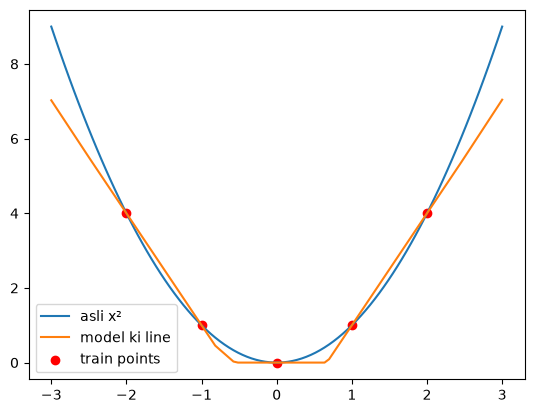

In [10]:
import matplotlib.pyplot as plt

xs = torch.linspace(-3, 3, 100).reshape(-1, 1)
with torch.no_grad():
    ys = model(xs)

plt.plot(xs.flatten(), xs.flatten() ** 2, label="asli x²")
plt.plot(xs.flatten(), ys.flatten(), label="model ki line")
plt.scatter(x.flatten(), y.flatten(), color="red", label="train points")
plt.legend()
plt.show()

loss: 0.0


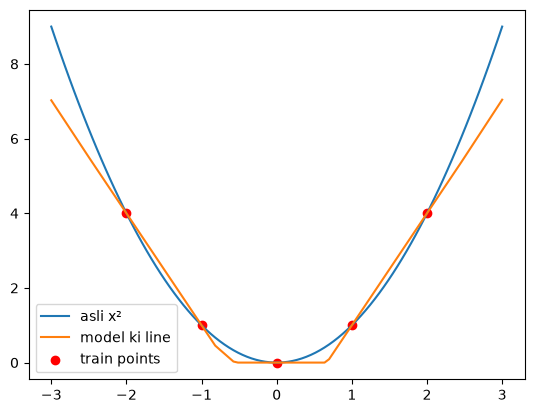

In [11]:
import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)

x = torch.tensor([[-2.0], [-1.0], [0.0], [1.0], [2.0]])
y = x ** 2

model = torch.nn.Sequential(
    torch.nn.Linear(1, 8),
    torch.nn.ReLU(),
    torch.nn.Linear(8, 1),
)
loss_fn = torch.nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=0.01)

for step in range(2000):
    loss = loss_fn(model(x), y)
    opt.zero_grad()
    loss.backward()
    opt.step()
print("loss:", round(loss.item(), 4))

xs = torch.linspace(-3, 3, 100).reshape(-1, 1)
with torch.no_grad():
    ys = model(xs)

plt.plot(xs.flatten(), xs.flatten() ** 2, label="asli x²")
plt.plot(xs.flatten(), ys.flatten(), label="model ki line")
plt.scatter(x.flatten(), y.flatten(), color="red", label="train points")
plt.legend()
plt.show()